# 16 · Estabilidad del aporte solar por periodo
Seminario de Tesis II · Greta Díaz Vega

Se reutilizan las predicciones Ridge de los cuadernos 14 y 15 emparejadas por índice, horizonte, origen, destino y valor observado. Se incluye una copia comprimida para ejecutar el cuaderno directamente. Los grupos se definen por el mes en que se emite el pronóstico.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io, gzip, base64

# Copia de las predicciones emparejadas
datos = "..."
pares = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(datos))), parse_dates=["origen","destino"])
print(len(pares), "pronósticos emparejados")

1486 pronósticos emparejados


## Errores de cada modelo
Una diferencia negativa (con SSN menos sin SSN) indica menor error al incorporar la actividad solar.

In [2]:
pares["periodo"] = pd.cut(pares.origen.dt.year, [2009,2014,2019,2026], labels=["2010–2014","2015–2019","2020 en adelante"])
filas = []
for (indice,h,periodo), grupo in pares.groupby(["indice","h","periodo"], observed=True):
    fila = dict(indice=indice, meses=h, periodo=periodo, inicio=grupo.origen.min().date(), fin=grupo.origen.max().date(), pares=len(grupo))
    for modelo in ["sin","con"]:
        error = grupo["estimado_"+modelo] - grupo.observado
        fila["MAE_"+modelo] = error.abs().mean()
        fila["RMSE_"+modelo] = np.sqrt((error**2).mean())
    for metrica in ["MAE","RMSE"]:
        fila["delta_"+metrica] = fila[metrica+"_con"] - fila[metrica+"_sin"]
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla.to_csv("16_estabilidad_por_periodo.csv",index=False)
print(tabla.round(4).to_string(index=False))

indice  meses          periodo     inicio        fin  pares  MAE_sin  RMSE_sin  MAE_con  RMSE_con  delta_MAE  delta_RMSE
  ICEN      3        2010–2014 2010-01-01 2014-12-01     60   0.4535    0.5767   0.4377    0.5556    -0.0157     -0.0211
  ICEN      3        2015–2019 2015-01-01 2019-12-01     60   0.5546    0.7180   0.5594    0.7189     0.0048      0.0009
  ICEN      3 2020 en adelante 2020-01-01 2026-02-01     74   0.6199    0.7794   0.5855    0.7496    -0.0344     -0.0299
  ICEN      6        2010–2014 2010-01-01 2014-12-01     60   0.6564    0.7773   0.6254    0.7415    -0.0310     -0.0358
  ICEN      6        2015–2019 2015-01-01 2019-12-01     60   0.7410    0.9396   0.7505    0.9437     0.0095      0.0040
  ICEN      6 2020 en adelante 2020-01-01 2025-11-01     71   0.8861    1.0835   0.8231    1.0369    -0.0629     -0.0466
  ICEN     12        2010–2014 2010-01-01 2014-12-01     60   0.7888    0.9813   0.7585    0.9669    -0.0303     -0.0143
  ICEN     12        2015–2019 2

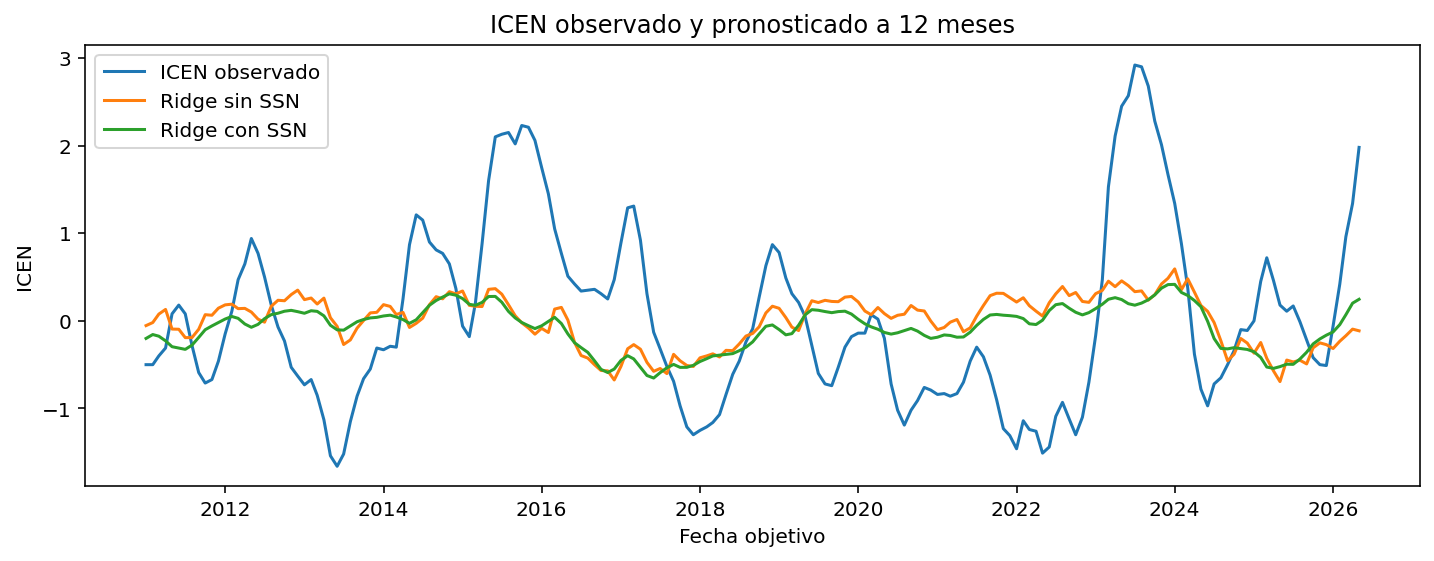

In [3]:
serie = pares.query("indice=='ICEN' and h==12").sort_values("destino")
fig,ax = plt.subplots(figsize=(10,4))
for columna,nombre in [("observado","ICEN observado"),("estimado_sin","Ridge sin SSN"),("estimado_con","Ridge con SSN")]:
    ax.plot(serie.destino,serie[columna],label=nombre,linewidth=1.5)
ax.set(xlabel="Fecha objetivo",ylabel="ICEN",title="ICEN observado y pronosticado a 12 meses")
ax.legend()
fig.tight_layout()
fig.savefig("16_ICEN_12_meses.png",dpi=180)
plt.show()

## Alcance
Los tres tramos pertenecen a la misma prueba retrospectiva. La comparación permite detectar cambios en el desempeño del modelo fijo. La magnitud y el signo de cada diferencia deben interpretarse junto con el número de pares y la variabilidad del índice.